In [1]:
#setup
import os, sys, time, math, json
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

from src.config import N, NUM_CELLS, MASK, VOCAB_SIZE
from src.groups import LEVEL_FLAT, NUM_LEVELS
from src.dataset import load
from src.sudoku import is_valid, count_violations, matches_clues, show

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device, "| levels:", NUM_LEVELS, "| MASK token:", MASK)

Using: cuda | levels: 3 | MASK token: 7


In [2]:
#load data
tr_p, tr_s = load("train")
va_p, va_s = load("val")
te_p, te_s = load("test")

def to_t(a):
    return torch.tensor(a.reshape(len(a), -1), dtype=torch.long, device=device)

Xtr, Ytr = to_t(tr_p), to_t(tr_s)
Xva, Yva = to_t(va_p), to_t(va_s)
print("train:", Xtr.shape, "| val:", Xva.shape)

train: torch.Size([19999, 36]) | val: torch.Size([1000, 36])


In [3]:
#what the model sees at each pass
LEVEL = torch.tensor(LEVEL_FLAT, dtype=torch.long, device=device)   # group id (0,1,2) of each cell

def make_state(puz, sol, k):
    """puz, sol: (B,36). k: (B,) pass number for each example."""
    state = torch.where(puz > 0, puz, torch.full_like(puz, MASK))     # blanks -> hidden
    reveal = LEVEL[None, :] < k[:, None]                               # cells of earlier passes
    return torch.where(reveal, sol, state)

def target_mask(puz, k):
    """Which cells the model must predict in pass k."""
    return (LEVEL[None, :] == k[:, None]) & (puz == 0)

# --- demo on one puzzle (7 means hidden) ---
puz, sol = Xtr[:1], Ytr[:1]
for k in range(NUM_LEVELS):
    kk = torch.tensor([k], device=device)
    print(f"Pass {k+1} input:")
    show(make_state(puz, sol, kk)[0].view(N, N).cpu().numpy())
    print("cells to predict:", int(target_mask(puz, kk).sum()), "\n")

Pass 1 input:
5 7 6 | 7 7 2 
7 4 7 | 7 7 7 
-------------
7 7 7 | 7 7 7 
1 3 7 | 7 7 5 
-------------
7 5 2 | 1 7 7 
7 7 7 | 7 2 3 
cells to predict: 6 

Pass 2 input:
5 1 6 | 7 7 2 
7 4 7 | 6 5 7 
-------------
6 7 5 | 7 7 7 
1 3 7 | 2 7 5 
-------------
7 5 2 | 1 7 7 
7 7 7 | 7 2 3 
cells to predict: 11 

Pass 3 input:
5 1 6 | 4 7 2 
2 4 7 | 6 5 1 
-------------
6 2 5 | 7 7 4 
1 3 4 | 2 6 5 
-------------
3 5 2 | 1 4 7 
7 6 7 | 5 2 3 
cells to predict: 7 



In [4]:
#attention without the mask
class SelfAttention(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dk = h, d // h
        self.qkv = nn.Linear(d, 3 * d)
        self.out = nn.Linear(d, d)

    def forward(self, x):                                   # (B, T, D)
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(B, T, self.h, self.dk).transpose(1, 2)
        k = k.view(B, T, self.h, self.dk).transpose(1, 2)
        v = v.view(B, T, self.h, self.dk).transpose(1, 2)

        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.dk)   # (B, h, T, T)
        att = att.softmax(dim=-1)        # <-- NO mask: every cell can see every cell

        y = (att @ v).transpose(1, 2).contiguous().view(B, T, D)
        return self.out(y)

class Block(nn.Module):
    def __init__(self, d, h, dff):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), SelfAttention(d, h)
        self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Linear(dff, d))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x

In [5]:
#NCM-lite model
D_MODEL, N_HEADS, N_LAYERS, D_FF = 128, 4, 4, 512      # same size as the transformer

class NCMLite(nn.Module):
    def __init__(self, vocab=VOCAB_SIZE, d=D_MODEL, h=N_HEADS, L=N_LAYERS, dff=D_FF):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(NUM_CELLS, d)
        self.cell_group = nn.Embedding(NUM_LEVELS, d)
        self.pass_emb = nn.Embedding(NUM_LEVELS, d)
        self.blocks = nn.ModuleList([Block(d, h, dff) for _ in range(L)])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)

    def forward(self, state, k):               # state (B,36), k (B,)
        x = (self.tok(state)
             + self.pos(torch.arange(NUM_CELLS, device=state.device))[None]
             + self.cell_group(LEVEL)[None]
             + self.pass_emb(k)[:, None, :])
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln_f(x))         # (B, 36, vocab): all 36 cells at once

model = NCMLite().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
out = model(Xtr[:2], torch.zeros(2, dtype=torch.long, device=device))
print(out.shape)       # (2, 36, 8)

Parameters: 800776
torch.Size([2, 36, 8])


In [6]:
#loss
def loss_fn(model, puz, sol):
    B = puz.shape[0]
    ks = torch.arange(NUM_LEVELS, device=puz.device).repeat_interleave(B)   # [0..0,1..1,2..2]
    P, S = puz.repeat(NUM_LEVELS, 1), sol.repeat(NUM_LEVELS, 1)
    state = make_state(P, S, ks)
    logits = model(state, ks)                                # (3B, 36, 8)
    m = target_mask(P, ks)                                   # (3B, 36)
    ce = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), S.reshape(-1),
                         reduction="none").view(-1, NUM_CELLS)
    loss = (ce * m).sum() / m.sum()
    acc = ((logits.argmax(-1) == S) & m).sum() / m.sum()
    return loss, acc

with torch.no_grad():
    l, a = loss_fn(model, Xtr[:256], Ytr[:256])
print(f"Initial loss: {l.item():.3f} (expect about 2.08) | acc: {a.item():.3f}")

Initial loss: 2.206 (expect about 2.08) | acc: 0.157


In [7]:
#train
EPOCHS, BATCH, LR = 20, 128, 1e-3
steps_per_epoch = math.ceil(len(Xtr) / BATCH)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)

os.makedirs("checkpoints", exist_ok=True)
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val, t0 = 1e9, time.time()

for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    total = 0.0
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        loss, _ = loss_fn(model, Xtr[idx], Ytr[idx])
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        total += loss.item() * len(idx)

    model.eval()
    with torch.no_grad():
        vl, va = loss_fn(model, Xva, Yva)
    history["train_loss"].append(total / len(Xtr))
    history["val_loss"].append(vl.item())
    history["val_acc"].append(va.item())
    if vl.item() < best_val:
        best_val = vl.item()
        torch.save(model.state_dict(), "checkpoints/ncm_best.pt")
    print(f"epoch {epoch+1:2d}/{EPOCHS} | train {history['train_loss'][-1]:.3f} "
          f"| val {vl.item():.3f} | val acc {va.item():.3f} | {time.time()-t0:.0f}s")

train_time = time.time() - t0

epoch  1/20 | train 1.847 | val 1.787 | val acc 0.209 | 30s
epoch  2/20 | train 1.598 | val 1.054 | val acc 0.561 | 60s
epoch  3/20 | train 0.439 | val 0.218 | val acc 0.905 | 90s
epoch  4/20 | train 0.182 | val 0.166 | val acc 0.929 | 119s
epoch  5/20 | train 0.143 | val 0.143 | val acc 0.938 | 149s
epoch  6/20 | train 0.121 | val 0.117 | val acc 0.949 | 178s
epoch  7/20 | train 0.105 | val 0.107 | val acc 0.954 | 207s
epoch  8/20 | train 0.095 | val 0.106 | val acc 0.955 | 237s
epoch  9/20 | train 0.084 | val 0.095 | val acc 0.958 | 266s
epoch 10/20 | train 0.076 | val 0.084 | val acc 0.964 | 296s
epoch 11/20 | train 0.066 | val 0.080 | val acc 0.967 | 325s
epoch 12/20 | train 0.058 | val 0.076 | val acc 0.968 | 355s
epoch 13/20 | train 0.049 | val 0.069 | val acc 0.970 | 384s
epoch 14/20 | train 0.041 | val 0.070 | val acc 0.972 | 414s
epoch 15/20 | train 0.034 | val 0.070 | val acc 0.973 | 443s
epoch 16/20 | train 0.026 | val 0.076 | val acc 0.973 | 472s
epoch 17/20 | train 0.020 |

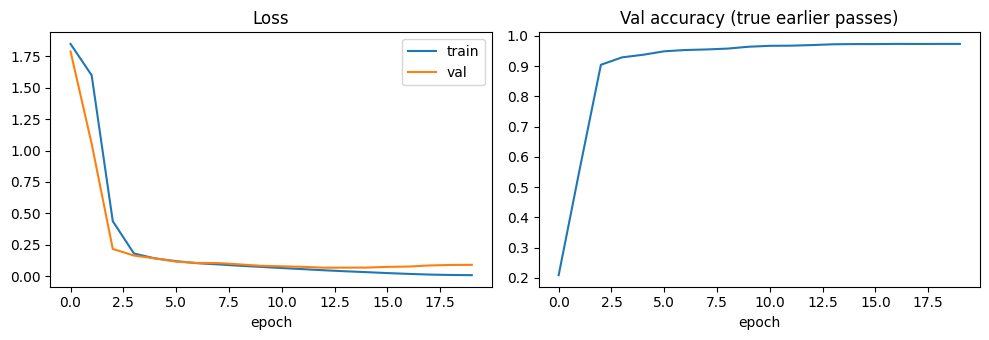

In [8]:
#learning curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_acc"]); ax[1].set_title("Val accuracy (true earlier passes)")
ax[1].set_xlabel("epoch")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/ncm_training_curves.png", dpi=150)
plt.show()

In [9]:
#real solving 
@torch.no_grad()
def solve_ncm(model, puz):                      # puz: (B,36)
    model.eval()
    B = puz.shape[0]
    state = torch.where(puz > 0, puz, torch.full_like(puz, MASK))
    for k in range(NUM_LEVELS):                 # only 3 forward passes
        kk = torch.full((B,), k, dtype=torch.long, device=puz.device)
        logits = model(state, kk)               # (B, 36, 8)
        pred = logits[:, :, 1:N + 1].argmax(-1) + 1
        fill = (LEVEL[None, :] == k) & (state == MASK)
        state = torch.where(fill, pred, state)
    return state

def evaluate(solver, puz_np, sol_np, passes, bs=500):
    puz = torch.tensor(puz_np.reshape(len(puz_np), -1), dtype=torch.long)
    preds = []
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for i in range(0, len(puz), bs):
        preds.append(solver(model, puz[i:i + bs].to(device)).cpu())
    if device.type == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - t
    preds = torch.cat(preds).numpy().reshape(-1, N, N)
    sol_np, puz_np = sol_np.astype(int), puz_np.astype(int)
    metrics = {
        "cell_accuracy": float((preds == sol_np).mean()),
        "valid_solution_pct": float(np.mean([is_valid(p) for p in preds])),
        "exact_match_pct": float(np.mean([(p == s).all() for p, s in zip(preds, sol_np)])),
        "clues_kept_pct": float(np.mean([matches_clues(p, q) for p, q in zip(preds, puz_np)])),
        "avg_violations": float(np.mean([count_violations(p) for p in preds])),
        "forward_passes": passes,
        "ms_per_puzzle": elapsed / len(puz) * 1000,
    }
    return metrics, preds

model.load_state_dict(torch.load("checkpoints/ncm_best.pt"))
metrics, preds = evaluate(solve_ncm, te_p, te_s, passes=NUM_LEVELS)
for k, v in metrics.items():
    print(f"{k:20s}: {v:.4f}")

metrics["train_time_sec"] = train_time
json.dump(metrics, open("results/ncm_metrics.json", "w"), indent=2)
np.save("results/ncm_test_preds.npy", preds)

cell_accuracy       : 0.9631
valid_solution_pct  : 0.7150
exact_match_pct     : 0.7150
clues_kept_pct      : 1.0000
avg_violations      : 1.1440
forward_passes      : 3.0000
ms_per_puzzle       : 0.6351


In [10]:
#which pass makes the mistakes?
P = te_p.reshape(len(te_p), -1)
S = te_s.reshape(len(te_s), -1)
Pr = preds.reshape(len(preds), -1)
blank = P == 0
for k in range(NUM_LEVELS):
    m = blank & (LEVEL_FLAT[None, :] == k)
    print(f"Pass {k+1}: accuracy on blank cells = {(Pr[m] == S[m]).mean():.3f}  ({m.sum()} cells)")

Pass 1: accuracy on blank cells = 0.923  (5963 cells)
Pass 2: accuracy on blank cells = 0.926  (5883 cells)
Pass 3: accuracy on blank cells = 0.928  (6056 cells)


In [11]:
#comaprison with the transformer
i = 0
print("PUZZLE");       show(te_p[i].astype(int))
print("\nNCM-lite OUTPUT"); show(preds[i])
print("\nTRUTH");        show(te_s[i].astype(int))
print("\nViolations in output:", count_violations(preds[i]))

ar = json.load(open("results/ar_metrics_forced.json"))
nc = json.load(open("results/ncm_metrics.json"))
print(f"\n{'metric':20s} {'Transformer':>12s} {'NCM-lite':>10s}")
for key in ["cell_accuracy", "valid_solution_pct", "exact_match_pct",
            "clues_kept_pct", "avg_violations", "forward_passes", "ms_per_puzzle"]:
    print(f"{key:20s} {ar[key]:12.4f} {nc[key]:10.4f}")

PUZZLE
6 2 . | . 3 4 
. . 3 | . 2 . 
-------------
3 . . | . . 5 
1 5 . | 4 6 . 
-------------
. 3 5 | . 4 1 
. 1 . | . . 2 

NCM-lite OUTPUT
6 2 1 | 5 3 4 
5 4 3 | 1 2 6 
-------------
3 6 4 | 2 1 5 
1 5 2 | 4 6 3 
-------------
2 3 5 | 6 4 1 
4 1 6 | 3 5 2 

TRUTH
6 2 1 | 5 3 4 
5 4 3 | 1 2 6 
-------------
3 6 4 | 2 1 5 
1 5 2 | 4 6 3 
-------------
2 3 5 | 6 4 1 
4 1 6 | 3 5 2 

Violations in output: 0

metric                Transformer   NCM-lite
cell_accuracy              0.9013     0.9631
valid_solution_pct         0.5320     0.7150
exact_match_pct            0.5320     0.7150
clues_kept_pct             1.0000     1.0000
avg_violations             2.0930     1.1440
forward_passes            36.0000     3.0000
ms_per_puzzle              9.5695     0.6351
